# Phase 2: training the shared swarm policy

One small MLP, copied onto every drone, turns what that drone sees into an acceleration:

$$a_i = a_{\max}\tanh\big(\mathrm{MLP}_\theta(o_i)\big), \qquad o_i = [\,k \text{ nearest neighbours},\ m \text{ nearest target points},\ v_i\,]$$

We train $\theta$ by rolling out the swarm in our differentiable simulator, scoring the final formation with the Chamfer loss (plus collision and effort penalties), and backpropagating through every step and every policy call.

All the logic lives in `swarm/`; this notebook only calls it, so the scripts and tests use exactly the same code.

| Section | What it shows |
|---|---|
| 1 | Setup |
| 2 | The training data: random scenes |
| 3 | What one drone sees |
| 4 | The untrained policy |
| 5 | Training, with live curves |
| 6 | Results on validation scenes |
| 7 | Generalization: shapes never seen in training |
| 8 | Scaling: trained on 32 drones, run with 64 |
| 9 | Self-healing: drones removed mid-flight |
| 10 | Policy vs the Phase 1 fixed plan |

## 1. Setup

In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import os, sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:   # find the repo root
    ROOT = ROOT.parent
os.chdir(ROOT)                              # so configs/, runs/ and results/ resolve
sys.path.insert(0, str(ROOT))               # so `import swarm` works

import time
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, clear_output, display

from swarm import viz
from swarm.config import load_config
from swarm.losses import chamfer
from swarm.observations import knn_offsets
from swarm.policy import SharedMLP, policy_from_config
from swarm.shapes import HELDOUT_SHAPES, TRAIN_SHAPES, random_shapes, sample_shape
from swarm.sim import rollout, rollout_closed_loop, rollout_with_removal
from swarm.train import evaluate, make_batch, train

cfg = load_config("configs/default.yaml")
cfg.device = "cpu"                          # "mps" for the Apple GPU (only ~1.3x faster at this size)
RUN = Path("runs/phase2")
GIFS, FIGS = Path("results/gifs"), Path("results/figures")

print(f"N = {cfg.n_agents} agents, T = {cfg.steps} steps, batch = {cfg.train.batch_size}, "
      f"iterations = {cfg.train.iters}, device = {cfg.device}")
print(f"policy: k = {cfg.policy.k_neighbors} neighbours, m = {cfg.policy.m_targets} target points, "
      f"{cfg.policy.layers} x {cfg.policy.hidden} hidden")
print("parameters:", sum(p.numel() for p in policy_from_config(cfg).parameters()))

N = 32 agents, T = 100 steps, batch = 32, iterations = 3000, device = cpu
policy: k = 6 neighbours, m = 8 target points, 2 x 64 hidden
parameters: 6274


## 2. The training data: random scenes

There is no dataset. Every iteration draws a fresh batch of scenes: start positions uniform in the box, and a random target shape, randomly rotated, stretched, resized and shifted. The policy never sees the same scene twice, so it has to learn a general skill. The shapes in `HELDOUT_SHAPES` are never used in training.

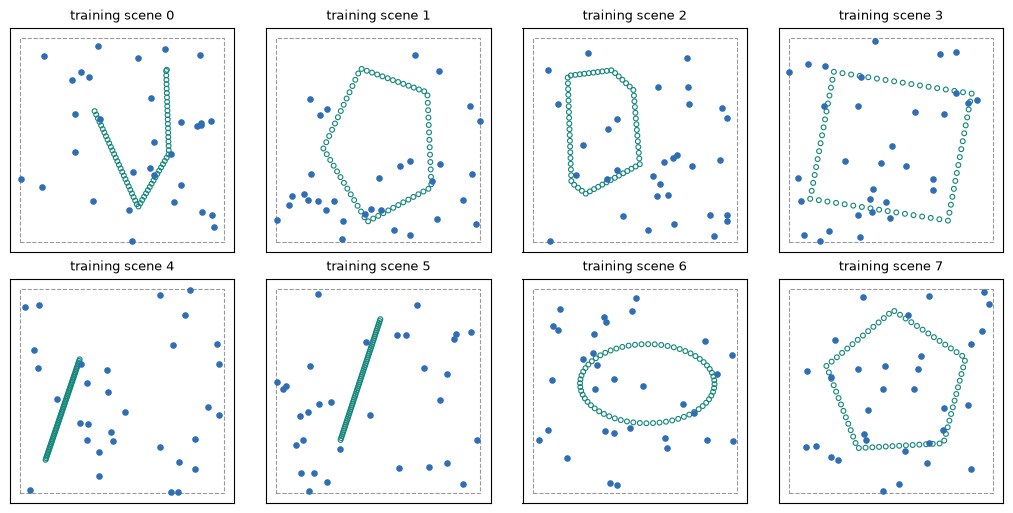

training shapes: ['circle', 'square', 'line', 'triangle', 'pentagon', 'random_polygon', 'random_polyline']
held out:        ['star', 'Z', 'M']


In [2]:
g = torch.Generator().manual_seed(42)
pos0, _, Q = make_batch(8, cfg.n_agents, cfg.dim, g)
fig = viz.plot_final_grid(pos0, Q, titles=[f"training scene {i}" for i in range(8)])
plt.show()
print("training shapes:", TRAIN_SHAPES)
print("held out:       ", HELDOUT_SHAPES)

## 3. What one drone sees

The blue dot is one drone. It sees only the orange lines (its 6 nearest drones) and the green lines (its 8 nearest target points), as offsets from itself, plus its own velocity. That is 30 numbers, however large the swarm is.

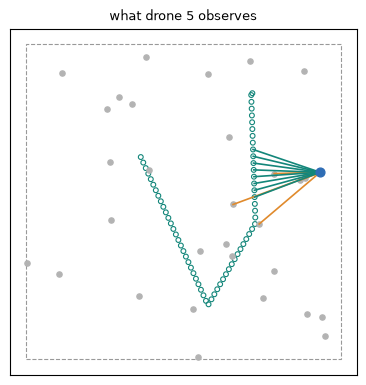

In [3]:
pos, Q1 = pos0[:1], Q[:1]
i = 5
nb = knn_offsets(pos, pos, cfg.policy.k_neighbors, exclude_self=True)[0, i]
tg = knn_offsets(pos, Q1, cfg.policy.m_targets)[0, i]
p = pos[0, i]

fig, ax = plt.subplots(figsize=(4.5, 4.5))
viz._setup(ax, Q1[0], "what drone 5 observes")
ax.scatter(*pos[0].T, s=14, color="0.7", zorder=2)
for o in nb:
    ax.plot(*torch.stack([p, p + o]).T, color="#E08A2C", lw=1.2)
for o in tg:
    ax.plot(*torch.stack([p, p + o]).T, color="#13867A", lw=1.2)
ax.scatter(*p, s=40, color="#2F6DB5", zorder=4)
plt.show()

## 4. The untrained policy

The output layer starts near zero, so before training every drone barely moves.

In [4]:
g_val = torch.Generator().manual_seed(cfg.train.val_seed)
val_batch = make_batch(cfg.train.val_scenes, cfg.n_agents, cfg.dim, g_val)   # same scenes train() validates on
untrained = policy_from_config(cfg)
print("untrained, validation scenes:", {k: round(v, 5) for k, v in evaluate(untrained, *val_batch, cfg).items()})
print("Chamfer of the start positions (no movement at all):", round(chamfer(val_batch[0], val_batch[2]).item(), 5))

untrained, validation scenes: {'chamfer': 0.07787, 'min_dist': 0.02163, 'collisions': 0.5625, 'speed': 0.00523}
Chamfer of the start positions (no movement at all): 0.07175


## 5. Training

Each iteration: 32 random scenes → closed-loop rollout (observe → policy → `sim.step`, T times) → loss → backward through every step → gradient clipping → Adam. The rollout length grows with a curriculum (40 → 70 → 100 steps) and the learning rate decays with a cosine schedule, a Phase 1 lesson.

The plot refreshes every 100 iterations. Validation uses 64 fixed scenes at full length. The best checkpoint is saved to `runs/phase2/best.pt`.

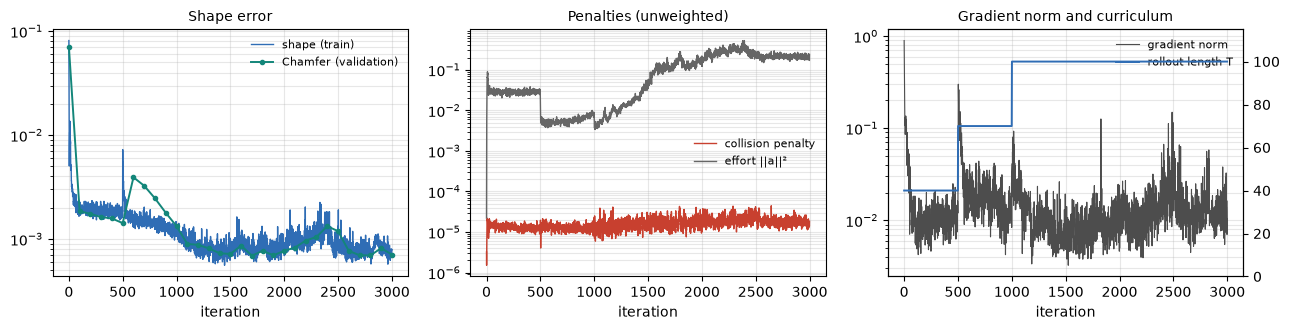

iteration 3000/3000   T = 100   train shape 0.00068   val Chamfer 0.00071 (it 3000)   |grad| 0.016   9.6 min


In [5]:
def live(history):
    clear_output(wait=True)
    viz.plot_training(history)
    plt.show()
    tr, val = history["train"][-1], history["val"][-1]
    print(f"iteration {tr['it'] + 1}/{cfg.train.iters}   T = {tr['T']}   train shape {tr['shape']:.5f}   "
          f"val Chamfer {val['chamfer']:.5f} (it {val['it']})   |grad| {tr['grad_norm']:.3f}   "
          f"{tr['time'] / 60:.1f} min")

policy, history = train(cfg, run_dir=RUN, callback=live, callback_every=100)
viz.plot_training(history, path=FIGS / "phase2_training.png")
plt.close()

## 6. Results on the validation scenes

In [6]:
ckpt = torch.load(RUN / "best.pt", weights_only=False)
policy = SharedMLP.load(RUN / "best.pt").eval()
print(f"best checkpoint: iteration {ckpt['it']}")

before = evaluate(untrained, *val_batch, cfg)
after = evaluate(policy, *val_batch, cfg)
print(f"{'':12s}{'Chamfer':>10s}{'min dist':>10s}{'collisions':>12s}{'end speed':>11s}")
for name, r in [("untrained", before), ("trained", after)]:
    print(f"{name:12s}{r['chamfer']:10.5f}{r['min_dist']:10.4f}{r['collisions']:12.2f}{r['speed']:11.3f}")
print("reference: Phase 1 optimum for 32 agents on a circle = 0.00058 (one scene, optimized directly)")

best checkpoint: iteration 1700


               Chamfer  min dist  collisions  end speed
untrained      0.07787    0.0216        0.56      0.005
trained        0.00069    0.0114       11.36      0.017
reference: Phase 1 optimum for 32 agents on a circle = 0.00058 (one scene, optimized directly)


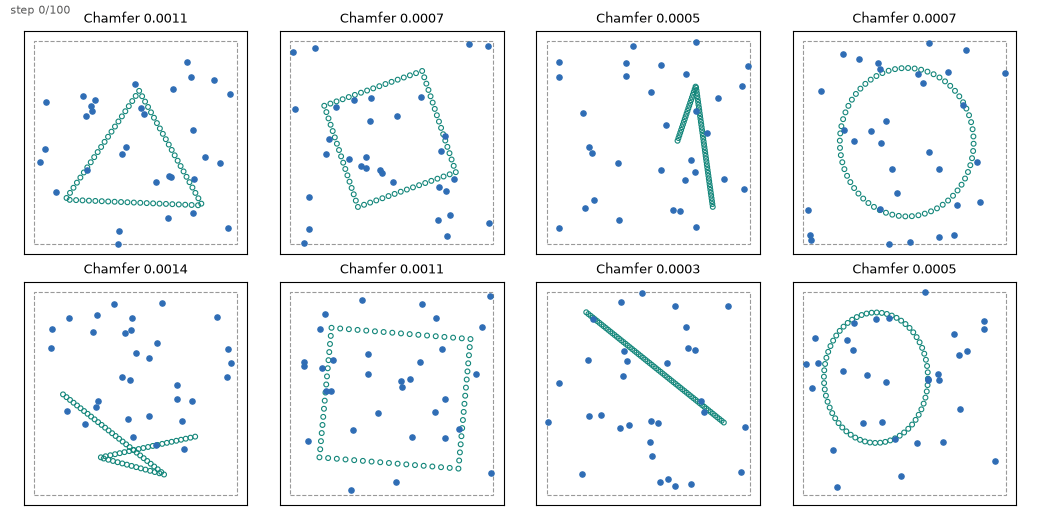

In [7]:
with torch.no_grad():
    traj, _ = rollout_closed_loop(*val_batch, policy.act, cfg)
S = 8
errs = [chamfer(traj[i:i + 1, -1], val_batch[2][i:i + 1]).item() for i in range(S)]
gif = viz.save_gif_grid(traj[:S, :, :, :], val_batch[2][:S], GIFS / "phase2_validation.gif",
                        titles=[f"Chamfer {e:.4f}" for e in errs])
display(Image(filename=gif))

## 7. Generalization: shapes never seen in training

A star, a Z and an M are not in the training set. Because each drone only sees nearby target points, it has no notion of which shape it is forming.

circle               Chamfer 0.00090
square               Chamfer 0.00310
star     (held out)  Chamfer 0.00273
Z        (held out)  Chamfer 0.00193
M        (held out)  Chamfer 0.00222


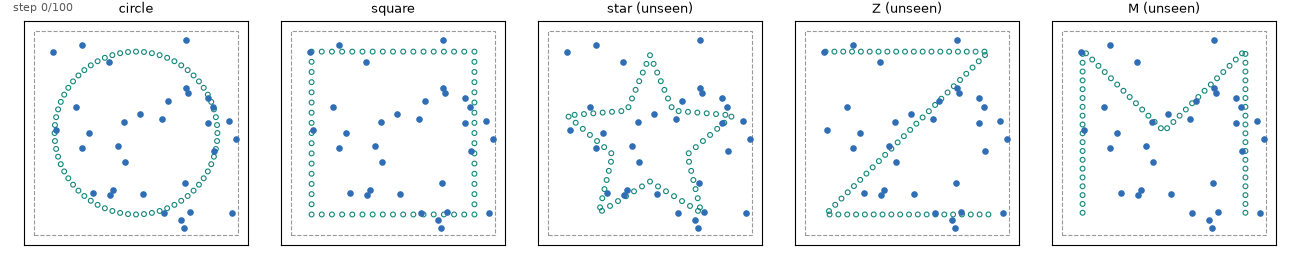

In [8]:
names = ["circle", "square"] + HELDOUT_SHAPES
g = torch.Generator().manual_seed(7)
pos0 = torch.rand(1, cfg.n_agents, cfg.dim, generator=g) - 0.5
trajs, Qs, gen_err = [], [], {}
with torch.no_grad():
    for name in names:
        Qn = sample_shape(name, 2 * cfg.n_agents)[None]
        tr, _ = rollout_closed_loop(pos0, torch.zeros_like(pos0), Qn, policy.act, cfg)
        trajs.append(tr[0]); Qs.append(Qn[0])
        gen_err[name] = chamfer(tr[:, -1], Qn).item()
for name, e in gen_err.items():
    print(f"{name:8s} {'(held out)' if name in HELDOUT_SHAPES else '          '}  Chamfer {e:.5f}")
gif = viz.save_gif_grid(trajs, Qs, GIFS / "phase2_unseen_shapes.gif",
                        titles=[f"{n}{' (unseen)' if n in HELDOUT_SHAPES else ''}" for n in names], cols=5)
display(Image(filename=gif))

## 8. Scaling: trained on 32 drones, run with 64

The observation has the same size for any N, so the same weights run on twice as many drones with no retraining. With 64 drones there are 128 target points, so the same Chamfer value means a denser, finer formation.

N =  16             Chamfer 0.00382   collisions 1.25   min dist 0.0157
N =  32  (trained)  Chamfer 0.00075   collisions 6.88   min dist 0.0114
N =  64             Chamfer 0.00030   collisions 68.50   min dist 0.0049


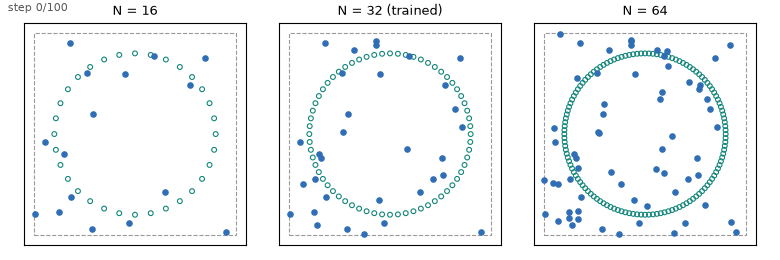

In [9]:
scale_err = {}
trajs, Qs = [], []
with torch.no_grad():
    for n in (16, 32, 64):
        g = torch.Generator().manual_seed(3)
        b = make_batch(32, n, cfg.dim, g)
        scale_err[n] = evaluate(policy, *b, cfg)
        tr, _ = rollout_closed_loop(b[0][:1], b[1][:1], sample_shape("circle", 2 * n)[None], policy.act, cfg)
        trajs.append(tr[0]); Qs.append(sample_shape("circle", 2 * n))
for n, r in scale_err.items():
    print(f"N = {n:3d}{'  (trained)' if n == cfg.n_agents else '           '}  Chamfer {r['chamfer']:.5f}   "
          f"collisions {r['collisions']:.2f}   min dist {r['min_dist']:.4f}")
gif = viz.save_gif_grid(trajs, Qs, GIFS / "phase2_scaling.gif", titles=["N = 16", "N = 32 (trained)", "N = 64"], cols=3)
display(Image(filename=gif))

## 9. Self-healing: 8 of 32 drones removed mid-flight

At step 60 we delete a quarter of the swarm. Nobody is told; the remaining drones just stop seeing them as neighbours, and the coverage gaps pull them apart to re-fill the shape.

circle {'before removal (step 60)': 0.00117, 'just after (step 61)': 0.00383, 'end (step 160)': 0.00216}
square {'before removal (step 60)': 0.00229, 'just after (step 61)': 0.00745, 'end (step 160)': 0.00574}


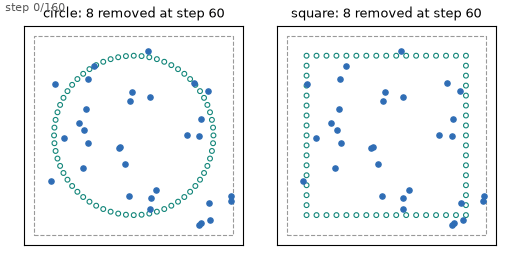

In [10]:
g = torch.Generator().manual_seed(11)
pos0 = torch.rand(1, cfg.n_agents, cfg.dim, generator=g) - 0.5
keep = torch.ones(cfg.n_agents, dtype=torch.bool)
keep[torch.randperm(cfg.n_agents, generator=g)[:8]] = False
trajs, Qs = [], []
heal = {}
for name in ["circle", "square"]:
    Qn = sample_shape(name, 2 * cfg.n_agents)[None]
    frames = rollout_with_removal(pos0, torch.zeros_like(pos0), Qn, policy.act, cfg, steps=160, remove_at=60, keep=keep)
    heal[name] = {
        "before removal (step 60)": chamfer(frames[60][None], Qn).item(),
        "just after (step 61)": chamfer(frames[61][None], Qn).item(),
        "end (step 160)": chamfer(frames[-1][None], Qn).item(),
    }
    trajs.append(frames); Qs.append(Qn[0])
for name, r in heal.items():
    print(name, {k: round(v, 5) for k, v in r.items()})
gif = viz.save_gif_grid(trajs, Qs, GIFS / "phase2_self_healing.gif",
                        titles=["circle: 8 removed at step 60", "square: 8 removed at step 60"], cols=2)
display(Image(filename=gif))

## 10. Policy vs the Phase 1 fixed plan

Phase 1 optimized 6,400 accelerations for one start. Here both methods face 16 new random starts on the circle. The plan is optimized once for start 0 and then replayed; the policy just runs.

In [11]:
torch.manual_seed(0)
N, T = cfg.n_agents, cfg.steps
Qc = sample_shape("circle", 2 * N)[None]
g = torch.Generator().manual_seed(0)
starts = torch.rand(16, N, cfg.dim, generator=g) - 0.5
vel0 = torch.zeros(1, N, cfg.dim)

raw = torch.zeros(1, T, N, cfg.dim, requires_grad=True)
opt = torch.optim.Adam([raw], lr=0.05)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, 300)
for _ in range(300):
    loss = chamfer(rollout(starts[:1], vel0, cfg.a_max * torch.tanh(raw), cfg)[:, -1], Qc)
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
plan = (cfg.a_max * torch.tanh(raw)).detach()

with torch.no_grad():
    plan_err = [chamfer(rollout(s[None], vel0, plan, cfg)[:, -1], Qc).item() for s in starts]
    pol_err = [chamfer(rollout_closed_loop(s[None], vel0, Qc, policy.act, cfg)[0][:, -1], Qc).item() for s in starts]

print(f"{'':28s}{'Phase 1 plan':>14s}{'policy':>10s}")
print(f"{'start it was optimized for':28s}{plan_err[0]:14.5f}{pol_err[0]:10.5f}")
print(f"{'15 new starts (mean)':28s}{sum(plan_err[1:]) / 15:14.5f}{sum(pol_err[1:]) / 15:10.5f}")

                              Phase 1 plan    policy
start it was optimized for         0.00065   0.00091
15 new starts (mean)               0.16409   0.00095


## Summary

In [12]:
print("Phase 2 results (Chamfer, lower is better)")
print(f"  validation scenes, untrained -> trained : {before['chamfer']:.5f} -> {after['chamfer']:.5f}")
print(f"  unseen shapes (star, Z, M), mean        : {sum(gen_err[n] for n in HELDOUT_SHAPES) / 3:.5f}")
print(f"  64 drones (trained on 32)               : {scale_err[64]['chamfer']:.5f}")
print(f"  self-healing circle, end of run         : {heal['circle']['end (step 160)']:.5f}")
print(f"  new starts: Phase 1 plan vs policy      : {sum(plan_err[1:]) / 15:.5f} vs {sum(pol_err[1:]) / 15:.5f}")
print(f"  training time                           : {history['train'][-1]['time'] / 60:.1f} min on {cfg.device}")

Phase 2 results (Chamfer, lower is better)
  validation scenes, untrained -> trained : 0.07787 -> 0.00069
  unseen shapes (star, Z, M), mean        : 0.00229
  64 drones (trained on 32)               : 0.00030
  self-healing circle, end of run         : 0.00216
  new starts: Phase 1 plan vs policy      : 0.16409 vs 0.00095
  training time                           : 9.6 min on cpu
